# Gráficos do pôster 

Este notebook lê a base consolidada (`bd8.csv` se baseando nas colunas do dicionário `dicionario_dados_educacionais_2011a2025.xlsx`) e gera:

1. **Quantidade de escolas integrais por dependência administrativa** 
2. **Expansão das escolas integrais por região** (mapa de calor) 
3. **Taxas de reprovação e abandono por modalidade, ano a ano** (escolas estaduais e municipais) 
4. **Boxplots de reprovação e abandono** por modalidade, nas escolas estaduais e municipais, comparando **pré-pandemia (2016–2019)** e **pós-pandemia (2022–2025)**.

**Decisões que valem para todo o notebook**

| Item | O que foi feito |
|---|---|
| Etapa | Só Ensino Médio (colunas `EM`) e só escolas-ano com matrícula no EM (`QT_MAT_EM_REG + QT_MAT_EM_INT > 0`). |
| Rendimento | Mantidas só as escolas-ano com `QT_APR_EM_TOTAL`, `QT_REP_EM_TOTAL` e `QT_ABN_EM_TOTAL` preenchidos.|
| Modalidade | `ENS_PRED_EM` da própria base (Regular < 10%, Misto 10–90%, Integral > 90% de matrículas integrais). |
| Dependência | Estadual e Municipal agrupadas em "Estadual/Municipal". |
| Taxa de uma escola | reprovados ÷ (aprovados + reprovados + abandonos) × 100 — a mesma fórmula do INEP. |
| Pandemia | 2020–2021 sombreados nos gráficos de linha. |


### Correções aplicadas

| | Problema | Onde foi corrigido |
|---|---|---|
| **C1** | A faixa da modalidade Misto aparecia como 48–52% (e Integral como "mais de 52%"). Na base, `ENS_PRED_EM` é Regular < 10%, Misto 10–90%, Integral > 90%. | `TEXTOS["g1_nota_abs"]` (seção 1) e o aviso em markdown da seção 7. |
| **C3** | No Gráfico 1, os rótulos percentuais de 2011 se sobrepunham. | `POSICOES_INICIO` (seção 5). |
| **C4** | A numeração dos gráficos não era a mesma em todo o notebook. | Introdução, títulos de seção, variáveis (`tab3`, `grafico3`, `tab4`, `base4`), `DEPS_GRAFICO3` e nomes dos arquivos (`g3_`, `g4_`, `tab3_`, `tab4_`). |

Trechos alterados no código estão marcados com `# [CORREÇÃO Cn]`.


## 0. Configuração

In [19]:
# ==========================================================
# CONFIGURAÇÕES GERAIS
# ==========================================================

from pathlib import Path

# Arquivos e diretórios
CAMINHO_BASE = Path("../01. Dados/bd8.csv")
PASTA_SAIDA = Path("figuras_poster")


# ==========================================================
# CATEGORIAS E PERÍODOS GERAIS
# ==========================================================

DEPS_TODAS = ["Federal", "Estadual/Municipal", "Privada"]
DEPS_PUBLICAS = ["Estadual/Municipal"]

ANOS_EXPANSAO = (2011, 2025)
ANOS_PANDEMIA = (2020, 2021)


# ==========================================================
# GRÁFICO 1 — EXPANSÃO NACIONAL
# Escolas integrais por dependência administrativa
# ==========================================================

DEPS_GRAFICO1 = DEPS_TODAS.copy()


# ==========================================================
# GRÁFICO 2 — EXPANSÃO REGIONAL
# Escolas integrais por região
# ==========================================================

DEPS_GRAFICO2 = DEPS_PUBLICAS.copy()


# ==========================================================
# GRÁFICO 3 — TAXAS POR MODALIDADE, ANO A ANO
# Reprovação e abandono agregados
# ==========================================================

DEPS_GRAFICO3 = DEPS_PUBLICAS.copy()


# ==========================================================
# GRÁFICO 4 — BOXPLOTS
# Pré (2016–2019) × pós-pandemia (2022–2025)
# ==========================================================

DEPS_GRAFICO4 = DEPS_PUBLICAS.copy()   # só escolas estaduais e municipais

PERIODOS_GRAFICO4 = {
    "pre": (2016, 2019),
    "pos": (2022, 2025)
}

UNIDADE_BOXPLOT = "escola-ano"
PESO_BOXPLOT = "alunos"

MIN_MATRICULAS_BOXPLOT = 0
MIN_N_CELULA_BOXPLOT = 30

## 1. Bibliotecas, cores e textos

In [20]:
# ===================== IMPORTAÇÕES ======================

import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch


# ===================== CONFIGURAÇÕES GERAIS ==============

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

REGIOES = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
MODALIDADES = ["Regular", "Misto", "Integral"]


# ===================== PALETAS DE CORES ==================

# Cores por região
COR_REGIAO = dict(zip(
    REGIOES,
    ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
))

# Cores por modalidade
COR_MOD = {
    "Regular": "#2a78d6",
    "Misto": "#eb6834",
    "Integral": "#1baf7a"
}

# Cores por período
COR_PERIODO = {
    "pre": "#9ec5f4",
    "pos": "#1c5cab"
}

# Cores por dependência administrativa
COR_DEPENDENCIA = {
    "Federal": "#6250d6",
    "Estadual/Municipal": "#008f72",
    "Privada": "#d95f59"
}

# Rampa de cores azuis para mapas de calor
RAMPA_AZUL = [
    "#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef",
    "#6da7ec", "#5598e7", "#3987e5", "#2a78d6",
    "#256abf", "#1c5cab", "#184f95", "#104281",
    "#0d366b"
]


# ===================== ESTILO VISUAL ====================

TINTA = "#0b0b0b"
TINTA_2 = "#52514e"
APAGADO = "#898781"

GRADE = "#e1e0d9"
EIXO = "#c3c2b7"
SOMBRA = "#efeee9"

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "figure.facecolor": "white",

    "font.family": "sans-serif",
    "font.size": 11,

    "axes.edgecolor": EIXO,
    "axes.linewidth": 0.8,
    "axes.labelcolor": TINTA_2,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlecolor": TINTA,

    "axes.spines.top": False,
    "axes.spines.right": False,

    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": GRADE,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,

    "xtick.color": EIXO,
    "ytick.color": EIXO,
    "xtick.labelcolor": TINTA_2,
    "ytick.labelcolor": TINTA_2,

    "legend.frameon": False,

    "lines.linewidth": 2.0,
    "lines.markersize": 4.5,

    "svg.fonttype": "none"
})


# ===================== TEXTOS DOS GRÁFICOS ================

# Todos os textos exibidos nos gráficos estão em inglês.

TEXTOS = {
    "ano": "Year",
    "regiao": "Region",
    "brasil": "Brazil",

    "modalidades": {
        "Regular": "Regular",
        "Misto": "Mixed",
        "Integral": "Full-time"
    },

    "dependencias": {
        "Federal": "Federal",
        "Estadual/Municipal": "State/Municipal",
        "Privada": "Private"
    },

    "periodos": {
        "pre": "Pre-pandemic",
        "pos": "Post-pandemic"
    },

    "pandemia": "2020–2021",

    "taxas": {
        "TX_REP": "Failure",
        "TX_ABN": "Dropout"
    },

    # GRÁFICOS 1 E 2 — EXPANSÃO

    "g1_titulo_pct": "Share of {escolas} classified as full-time",
    "g1_titulo_abs": "Number of {escolas} classified as full-time",

    "g1_y_pct": "Full-time schools (% of the region's schools)",
    "g1_y_abs": "Full-time schools",

    "g1_nota_pct": (
        "Share = full-time schools ÷ {escolas} "
        "with pass/fail/dropout data, in each region and year."
    ),

    "g1_nota_abs": (
        "Count of {escolas} classified as full-time "
        # [CORREÇÃO C1] faixa real de ENS_PRED_EM: Integral = mais de 90% das matrículas do EM
        "(more than 90% of high school enrollment in full-time classes)."
    ),

    "g2_heat_titulo": "Share of {escolas} classified as full-time (%)",

    "g2_halter_titulo": (
        "Share of {escolas} classified as full-time, {a0} vs {a1}"
    ),

    "g2_halter_x": "Full-time schools (% of the region's schools)",

    "pp": "p.p.",

    # GRÁFICO 3 — TAXAS AGREGADAS

    "g3_titulo_pct": "Failure and dropout rates by school schedule",

    "g3_titulo_abs": (
        "Students who failed or dropped out, by school schedule"
    ),

    "g3_sub": "{taxa}",
    "g3_y_pct": "Rate (%)",
    "g3_y_abs": "Students (thousands)",

    "g3_nota_pct": (
        "Aggregate rate = students who failed (or dropped out) "
        "÷ students with a final status (passed + failed + dropped out), "
        "summed over {escolas}. Shading: 2020–2021."
    ),

    "g3_nota_abs": (
        "Estimated counts (school rate × enrollment, INEP). "
        "Totals reflect both the rate and the size of each schedule group. "
        "Shading: 2020–2021."
    ),

    # GRÁFICO 4 — BOXPLOTS

    "g4_titulo": "High school failure and dropout rates by school schedule",

    # Subtítulo dos Gráficos 3 e 4 (mesmo texto do subtítulo do Gráfico 2)
    "subtitulo_publicas": "State and municipal schools",

    "g4_y": "{taxa} rate (%)",

    "g4_nota_peso": (
        "Each box: distribution of school rates weighted "
        "by the school's number of high school students. "
    ),

    "g4_nota_sem_peso": (
        "Each box: distribution of school rates, "
        "each {unidade} counted once. "
    ),

    "g4_nota_fim": (
        "Whiskers: most extreme value within 1.5 × IQR; "
        "outliers hidden. Hatched boxes: fewer than {n} {unidade}s."
    ),

    "unidades": {
        "escola-ano": "school-year",
        "escola-periodo": "school-period"
    },

    "n_baixo": "n < {n}",

    "dependencias_txt": {
        "Federal": "federal",
        "Estadual/Municipal": "state/municipal",
        "Privada": "private"
    },

    "escolas_de": "{deps} high schools",
    "escolas_todas": "high schools (all administrative categories)"
}


# ===================== FUNÇÕES AUXILIARES ================

def nome_deps(deps):
    """Gera uma descrição das dependências administrativas selecionadas."""

    if set(deps) == set(DEPS_TODAS):
        return TEXTOS["escolas_todas"]

    return TEXTOS["escolas_de"].format(
        deps=" + ".join(TEXTOS["dependencias_txt"][d] for d in deps)
    )


# Formatadores dos eixos
PCT = mticker.FuncFormatter(
    lambda v, _: f"{v:g}%" if v >= 0 else ""
)

MIL = mticker.StrMethodFormatter("{x:,.0f}")


def sombra_pandemia(ax):
    """Destaca o período pandêmico no gráfico."""

    ax.axvspan(
        ANOS_PANDEMIA[0] - 0.5,
        ANOS_PANDEMIA[1] + 0.5,
        color=SOMBRA,
        lw=0,
        zorder=0
    )


def eixo_anos(ax, anos):
    """Padroniza a exibição dos anos no eixo horizontal."""

    ax.set_xticks(range(min(anos), max(anos) + 1, 2))
    ax.set_xlim(min(anos) - 0.4, max(anos) + 0.4)
    ax.xaxis.set_minor_locator(mticker.NullLocator())


def rotulos_finais(ax, x, valores, textos, folga=0.055):
    """Adiciona rótulos à direita do último ponto, evitando sobreposição."""

    y0, y1 = ax.get_ylim()
    passo = folga * (y1 - y0)

    itens = sorted(zip(valores, textos))
    posicoes = []

    for v, _ in itens:
        posicoes.append(
            v if not posicoes or v - posicoes[-1] >= passo
            else posicoes[-1] + passo
        )

    for (v, txt), y in zip(itens, posicoes):
        ax.annotate(
            txt,
            xy=(x, v),
            xytext=(x + 0.45, y),
            textcoords="data",
            va="center",
            ha="left",
            fontsize=9,
            color=TINTA_2,
            annotation_clip=False
        )


def nota(fig, texto, y=-0.01, largura=150):
    """Adiciona uma nota explicativa abaixo do gráfico."""

    fig.text(
        0.01,
        y,
        textwrap.fill(texto, largura),
        ha="left",
        va="top",
        fontsize=8,
        color=APAGADO
    )


def salvar(fig, nome):
    """Salva o gráfico nos formatos PNG e SVG."""

    for ext in ("png", "svg"):
        fig.savefig(
            PASTA_SAIDA / f"{nome}.{ext}",
            bbox_inches="tight",
            facecolor="white"
        )

    print(f"Salvo: {PASTA_SAIDA / nome}.png / .svg")

## 2. Leitura da base

In [21]:
# ===================== LEITURA DA BASE ==================

# Colunas numéricas necessárias para as análises
COLS_NUM = [
    "QT_MAT_EM_REG",
    "QT_MAT_EM_INT",
    "QT_APR_EM_TOTAL",
    "QT_REP_EM_TOTAL",
    "QT_ABN_EM_TOTAL"
]

COLS = [
    "ANO",
    "CO_ESCOLA",
    "REGIAO",
    "DEP_ADM",
    "ENS_PRED_EM"
] + COLS_NUM


# ===================== IDENTIFICAÇÃO DO SEPARADOR ========

with open(CAMINHO_BASE, encoding="utf-8-sig") as f:
    cabecalho = f.readline()

SEP = ";" if cabecalho.count(";") > cabecalho.count(",") else ","


# ===================== IDENTIFICAÇÃO DAS COLUNAS =========

# Ler somente o cabeçalho para identificar os nomes originais
colunas_originais = pd.read_csv(
    CAMINHO_BASE,
    sep=SEP,
    encoding="utf-8-sig",
    nrows=0
).columns

# Preservar identificadores e códigos como texto
COLS_TEXTO = {
    c: "string"
    for c in colunas_originais
    if c.strip() in ["CO_ESCOLA", "DEP_ADM"]
}


# ===================== CARREGAMENTO ======================

bruta = pd.read_csv(
    CAMINHO_BASE,
    sep=SEP,
    encoding="utf-8-sig",
    low_memory=False,
    usecols=lambda c: c.strip() in COLS,
    dtype=COLS_TEXTO
)

# Remover espaços dos nomes das colunas
bruta.columns = bruta.columns.str.strip()

# Verificar se todas as colunas necessárias foram encontradas
faltando = set(COLS) - set(bruta.columns)

assert not faltando, (
    f"Colunas não encontradas na base: {faltando}"
)


# ===================== CONVERSÃO NUMÉRICA ================

# Converter variáveis numéricas, aceitando vírgula decimal
for c in COLS_NUM + ["ANO"]:

    bruta[c] = pd.to_numeric(
        bruta[c]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

# Ano como inteiro anulável
bruta["ANO"] = bruta["ANO"].astype("Int64")


# ===================== PADRONIZAÇÃO DAS CATEGORIAS =======

# Identificador da escola como texto
bruta["CO_ESCOLA"] = (
    bruta["CO_ESCOLA"]
    .astype("string")
    .str.strip()
)

# Região
bruta["REGIAO"] = (
    bruta["REGIAO"]
    .astype("string")
    .str.strip()
    .str.replace("_", "-", regex=False)
    .str.title()
)

# Modalidade predominante
bruta["ENS_PRED_EM"] = (
    bruta["ENS_PRED_EM"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Dependência administrativa original
bruta["DEP_ADM"] = (
    bruta["DEP_ADM"]
    .astype("string")
    .str.strip()
)


# ===================== AGRUPAMENTO DAS DEPENDÊNCIAS ======

MAPA_DEP = {
    # Federal
    "federal": "Federal",
    "1": "Federal",

    # Estadual e municipal
    "estadual": "Estadual/Municipal",
    "2": "Estadual/Municipal",
    "municipal": "Estadual/Municipal",
    "3": "Estadual/Municipal",
    "estadual/municipal": "Estadual/Municipal",
    "estadual e municipal": "Estadual/Municipal",

    # Privada
    "privada": "Privada",
    "4": "Privada"
}

dep_normalizada = (
    bruta["DEP_ADM"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s*/\s*", "/", regex=True)
    .str.replace(r"\.0$", "", regex=True)
)

bruta["DEP"] = dep_normalizada.map(MAPA_DEP)


# ===================== DIAGNÓSTICO INICIAL ================

print(f"Separador identificado: '{SEP}'")
print(f"Linhas carregadas: {len(bruta):,}")
print(f"Período: {bruta['ANO'].min()}–{bruta['ANO'].max()}")

print("\nRegiões:")
print(sorted(bruta["REGIAO"].dropna().unique()))

print("\nModalidades:")
print(sorted(bruta["ENS_PRED_EM"].dropna().unique()))

print("\nDependências administrativas (original → agrupada):")

display(
    bruta[["DEP_ADM", "DEP"]]
    .drop_duplicates()
    .sort_values("DEP_ADM", na_position="last")
    .set_index("DEP_ADM")
)

# Identificar categorias que não foram reconhecidas
nao_mapeadas = (
    bruta.loc[bruta["DEP"].isna(), "DEP_ADM"]
    .value_counts(dropna=False)
)

if not nao_mapeadas.empty:
    print("\nATENÇÃO: dependências não reconhecidas:")
    display(nao_mapeadas.to_frame("quantidade"))
else:
    print("\nTodas as dependências administrativas foram reconhecidas!")

Separador identificado: ';'
Linhas carregadas: 2,051,631
Período: 2011–2025

Regiões:
['Centro-Oeste', 'Nordeste', 'Norte', 'Sudeste', 'Sul']

Modalidades:
['Integral', 'Misto', 'Regular']

Dependências administrativas (original → agrupada):


,DEP
DEP_ADM,
Estadual,Estadual/Municipal
Federal,Federal
Municipal,Estadual/Municipal
Privada,Privada



Todas as dependências administrativas foram reconhecidas!


## 3. Filtragem da base 

In [22]:
# ==========================================================
# FILTROS E DEFINIÇÃO DA AMOSTRA COMUM
# ==========================================================

# Colunas utilizadas nas análises de rendimento
COLS_RENDIMENTO = [
    "QT_APR_EM_TOTAL",
    "QT_REP_EM_TOTAL",
    "QT_ABN_EM_TOTAL"
]

# Colunas de matrícula no Ensino Médio
COLS_MATRICULAS_EM = [
    "QT_MAT_EM_REG",
    "QT_MAT_EM_INT"
]

etapas_filtros = []


# ----------------------------------------------------------
# ETAPA 0 — PREPARAÇÃO DAS VARIÁVEIS
# ----------------------------------------------------------

bruta = bruta.copy()

for coluna in COLS_MATRICULAS_EM + COLS_RENDIMENTO:
    bruta[coluna] = pd.to_numeric(
        bruta[coluna],
        errors="coerce"
    )

etapas_filtros.append(
    ("Registros na base original", len(bruta))
)


# ----------------------------------------------------------
# ETAPA 1 — ESCOLAS COM ENSINO MÉDIO
# ----------------------------------------------------------

bruta["MAT_EM"] = bruta[COLS_MATRICULAS_EM].sum(
    axis=1,
    min_count=1
)

df_em = bruta.loc[
    bruta["MAT_EM"] > 0
].copy()

etapas_filtros.append(
    ("Com matrícula no Ensino Médio", len(df_em))
)


# ----------------------------------------------------------
# ETAPA 2 — MODALIDADE, DEPENDÊNCIA E REGIÃO RECONHECIDAS
# ----------------------------------------------------------

mask_modalidade = df_em["ENS_PRED_EM"].isin(MODALIDADES)
mask_dependencia = df_em["DEP"].isin(DEPS_TODAS)
mask_regiao = df_em["REGIAO"].isin(REGIOES)

sem_modalidade = ~mask_modalidade

sem_dependencia_regiao = (
    mask_modalidade
    & (~mask_dependencia | ~mask_regiao)
)

df_caracteristicas = df_em.loc[
    mask_modalidade & mask_dependencia & mask_regiao
].copy()

etapas_filtros.append(
    (
        "Descartadas: modalidade não reconhecida",
        int(sem_modalidade.sum())
    )
)

etapas_filtros.append(
    (
        "Descartadas: dependência ou região não reconhecida",
        int(sem_dependencia_regiao.sum())
    )
)

etapas_filtros.append(
    (
        "Com modalidade, dependência e região reconhecidas",
        len(df_caracteristicas)
    )
)


# ----------------------------------------------------------
# ETAPA 3 — RENDIMENTO COMPLETO
# ----------------------------------------------------------

# Exigimos aprovação, reprovação e abandono informados.
sem_rendimento = (
    df_caracteristicas[COLS_RENDIMENTO]
    .isna()
    .any(axis=1)
)

df_com_rendimento = df_caracteristicas.loc[
    ~sem_rendimento
].copy()

etapas_filtros.append(
    (
        "Descartadas: rendimento incompleto",
        int(sem_rendimento.sum())
    )
)

# Total de alunos com situação final informada
df_com_rendimento["ALUNOS"] = (
    df_com_rendimento[COLS_RENDIMENTO]
    .sum(axis=1, min_count=3)
)


# ----------------------------------------------------------
# ETAPA 4 — DENOMINADOR POSITIVO
# ----------------------------------------------------------

sem_denominador = (
    df_com_rendimento["ALUNOS"].isna()
    | (df_com_rendimento["ALUNOS"] <= 0)
)

df_analise = df_com_rendimento.loc[
    ~sem_denominador
].copy()

etapas_filtros.append(
    (
        "Descartadas: total de alunos igual a zero ou inválido",
        int(sem_denominador.sum())
    )
)


# ----------------------------------------------------------
# ETAPA 5 — CÁLCULO DAS TAXAS DE RENDIMENTO
# ----------------------------------------------------------

df_analise["TX_APR"] = (
    100 * df_analise["QT_APR_EM_TOTAL"]
    / df_analise["ALUNOS"]
)

df_analise["TX_REP"] = (
    100 * df_analise["QT_REP_EM_TOTAL"]
    / df_analise["ALUNOS"]
)

df_analise["TX_ABN"] = (
    100 * df_analise["QT_ABN_EM_TOTAL"]
    / df_analise["ALUNOS"]
)

# Identificação das escolas classificadas como integrais
df_analise["INTEGRAL"] = (
    df_analise["ENS_PRED_EM"].eq("Integral")
)

etapas_filtros.append(
    (
        "AMOSTRA FINAL COMUM (Gráficos 1 a 4)",
        len(df_analise)
    )
)


# ----------------------------------------------------------
# ETAPA 6 — CONFERÊNCIA DE DUPLICATAS
# ----------------------------------------------------------

duplicadas = int(
    df_analise.duplicated(
        subset=["ANO", "CO_ESCOLA"]
    ).sum()
)

etapas_filtros.append(
    (
        "Duplicatas escola-ano na amostra comum",
        duplicadas
    )
)


# ----------------------------------------------------------
# ETAPA 7 — RESUMO DOS FILTROS
# ----------------------------------------------------------

resumo_amostra = pd.DataFrame(
    etapas_filtros,
    columns=["Etapa", "Registros"]
).set_index("Etapa")

resumo_amostra.to_csv(
    PASTA_SAIDA / "tab0_filtros_amostra_comum.csv",
    encoding="utf-8-sig"
)

print("FILTROS — AMOSTRA COMUM")
display(resumo_amostra)

print(
    f"\nEscolas distintas na amostra comum: "
    f"{df_analise['CO_ESCOLA'].nunique():,}".replace(",", ".")
)

print(
    f"Registros escola-ano: "
    f"{len(df_analise):,}".replace(",", ".")
)

print(
    f"Taxas de rendimento calculadas: "
    f"{len(df_analise):,}".replace(",", ".")
)


# ----------------------------------------------------------
# ETAPA 8 — DISTRIBUIÇÃO DAS MODALIDADES
# ----------------------------------------------------------

print("\nDISTRIBUIÇÃO DAS MODALIDADES — AMOSTRA COMUM")

distribuicao_modalidades = (
    pd.crosstab(
        df_analise["ANO"],
        df_analise["ENS_PRED_EM"]
    )
    .reindex(columns=MODALIDADES, fill_value=0)
)

distribuicao_modalidades["Total"] = (
    distribuicao_modalidades.sum(axis=1)
)

display(distribuicao_modalidades)

distribuicao_modalidades.to_csv(
    PASTA_SAIDA / "tab0_distribuicao_modalidades.csv",
    encoding="utf-8-sig"
)


# ----------------------------------------------------------
# ETAPA 9 — CONFERÊNCIA FINAL
# ----------------------------------------------------------

print("\nCONFERÊNCIA FINAL")

print(f"Registros para os quatro gráficos: {len(df_analise):,}")

print(
    "\nModalidades:"
)

print(
    df_analise["ENS_PRED_EM"].value_counts().to_dict()
)

print(
    "\nDependências:"
)

print(
    df_analise["DEP"].value_counts().to_dict()
)

print(
    "\nRegiões:"
)

print(
    df_analise["REGIAO"].value_counts().to_dict()
)

print(
    f"\nDuplicatas escola-ano: {duplicadas}"
)

FILTROS — AMOSTRA COMUM


,Registros
Etapa,
Registros na base original,2051631
Com matrícula no Ensino Médio,429001
Descartadas: modalidade não reconhecida,0
Descartadas: dependência ou região não reconhecida,0
"Com modalidade, dependência e região reconhecidas",429001
Descartadas: rendimento incompleto,2873
Descartadas: total de alunos igual a zero ou inválido,0
AMOSTRA FINAL COMUM (Gráficos 1 a 4),426128
Duplicatas escola-ano na amostra comum,0



Escolas distintas na amostra comum: 36.851
Registros escola-ano: 426.128
Taxas de rendimento calculadas: 426.128

DISTRIBUIÇÃO DAS MODALIDADES — AMOSTRA COMUM


ENS_PRED_EM,Regular,Misto,Integral,Total
ANO,,,,
2011,25451,632,492,26575
2012,25546,828,643,27017
2013,25517,1064,794,27375
2014,25548,1062,1002,27612
2015,25611,1029,1203,27843
2016,25703,1092,1359,28154
2017,25496,1305,1609,28410
2018,25064,1603,1854,28521
2019,24971,1512,2154,28637



CONFERÊNCIA FINAL
Registros para os quatro gráficos: 426,128

Modalidades:
{'Regular': 360149, 'Integral': 35237, 'Misto': 30742}

Dependências:
{'Estadual/Municipal': 295664, 'Privada': 122811, 'Federal': 7653}

Regiões:
{'Sudeste': 183255, 'Nordeste': 105510, 'Sul': 67344, 'Norte': 35934, 'Centro-Oeste': 34085}

Duplicatas escola-ano: 0


## 4. Atribuição de peso

#### Nomes usados nas seções 4, 7 e 8

Esta célula só cria apelidos para objetos já definidos acima, sem recalcular nada: `df` é a mesma amostra comum (`df_analise`).

In [23]:
# ===================== APELIDOS =====================
# Nenhum cálculo novo: só aponta os nomes usados nas seções 4, 7 e 8
# para os objetos e configurações já definidos acima.

df = df_analise                          # amostra comum (Gráficos 1 a 4)
SAIDA = PASTA_SAIDA
IDIOMA = "en"                            # TEXTOS está em inglês
PERIODOS = PERIODOS_GRAFICO4
UNIDADE_BOX = UNIDADE_BOXPLOT
MIN_N_CELULA = MIN_N_CELULA_BOXPLOT

print(f"Escolas-ano na amostra usada pelos Gráficos 3 e 4: {len(df):,}")

Escolas-ano na amostra usada pelos Gráficos 3 e 4: 426,128


### Porte das escolas e a escolha do peso

**O problema.** Numa escola com 8 alunos no EM, um único reprovado vira 12,5% de reprovação. Escolas pequenas produzem taxas extremas por acaso e alargam as caixas dos boxplots.

**Classificação oficial encontrada.** O INEP não publica uma classificação de porte isolada; o porte aparece como um dos quatro componentes do **Indicador de Complexidade de Gestão da Escola** (Nota Técnica INEP, 2014), medido pelo número de matrículas de escolarização, em seis faixas: **até 50; 51–150; 151–300; 301–500; 501–1.000; mais de 1.000**. Usamos essas faixas aplicadas às **matrículas do Ensino Médio** — isso é uma adaptação nossa: na nota técnica o porte se refere ao total de matrículas da escola, e a base não tem todas as etapas (infantil, EJA, profissional).

**O que fazer com o peso, gráfico a gráfico**

- **Gráfico 3 (linhas de taxa):** não precisa de peso extra. A taxa agregada (soma dos reprovados ÷ soma dos alunos) já é uma média ponderada pelo número de alunos: uma escola de 10 alunos pesa 10, uma de 1.000 pesa 1.000.
- **Gráfico 4 (boxplots):** aqui cada escola contaria igual. Sugestão: **ponderar cada escola pelo número de alunos** (`PESO_BOXPLOT = "alunos"`). A leitura da caixa passa a ser "taxa da escola em que o aluno estuda". Alternativa mais simples de explicar: sem peso, mas tirando a faixa "até 50" (`MIN_MATRICULAS_BOXPLOT = 51`). A tabela de sensibilidade no fim do notebook mostra se a escolha muda a conclusão.
- **Gráficos 1 e 2 (contagem de escolas):** a unidade é a escola, então não se aplica peso.

A tabela abaixo mostra a dispersão das taxas por faixa de porte — se as faixas pequenas tiverem caixas (P25–P75) e P90 bem maiores, o argumento do peso está confirmado nos dados de vocês.

In [24]:
FAIXAS = [0, 50, 150, 300, 500, 1000, np.inf]
ROTULOS_PORTE = ["até 50", "51–150", "151–300", "301–500", "501–1.000", "mais de 1.000"]
df["PORTE"] = pd.cut(df["MAT_EM"], FAIXAS, labels=ROTULOS_PORTE)

com_taxa = df[df["ALUNOS"] > 0]
tab_porte = com_taxa.groupby("PORTE", observed=False).agg(
    escolas_ano=("CO_ESCOLA", "size"),
    alunos=("ALUNOS", "sum"),
    rep_P25=("TX_REP", lambda s: s.quantile(.25)),
    rep_mediana=("TX_REP", "median"),
    rep_P75=("TX_REP", lambda s: s.quantile(.75)),
    rep_P90=("TX_REP", lambda s: s.quantile(.90)),
    abn_mediana=("TX_ABN", "median"),
    abn_P90=("TX_ABN", lambda s: s.quantile(.90)),
    pct_rep_zero=("TX_REP", lambda s: 100 * (s == 0).mean()),
)
tab_porte.insert(1, "% escolas-ano", 100 * tab_porte["escolas_ano"] / tab_porte["escolas_ano"].sum())
tab_porte.insert(3, "% alunos", 100 * tab_porte["alunos"] / tab_porte["alunos"].sum())
tab_porte.to_csv(SAIDA / "tab_porte.csv", encoding="utf-8-sig")
display(tab_porte.round(1))

,escolas_ano,% escolas-ano,alunos,% alunos,rep_P25,rep_mediana,rep_P75,rep_P90,abn_mediana,abn_P90,pct_rep_zero
PORTE,,,,,,,,,,,
até 50,56311,13.2,1736331.0,1.5,0.0,0.0,4.8,12.0,0.0,10.0,59.3
51–150,126899,29.8,11955895.0,10.1,0.0,2.7,7.3,13.8,0.0,10.5,28.7
151–300,101207,23.8,22105754.0,18.7,1.2,4.7,10.6,17.8,1.8,14.2,15.0
301–500,74055,17.4,28842858.0,24.4,1.8,6.0,12.6,19.9,3.0,14.8,11.5
501–1.000,55321,13.0,37360644.0,31.5,2.8,8.0,14.8,22.0,4.5,16.1,8.5
mais de 1.000,12335,2.9,16424546.0,13.9,4.4,10.6,17.4,24.3,5.6,18.3,6.2


## 5. Gráfico 1 - Evolução da mudança de modalidade



O gráfico 1 analisa a evolução da modalidade no conjunto de escolas de cada dependência administrativa (Federal, Estadual/Municipal e Privada), ao longo do período analisado (2011-2025).

#### Tabela 

In [25]:
# ==========================================================
# GRÁFICO 1 — EXPANSÃO NACIONAL
# Escolas integrais por dependência administrativa
# ==========================================================


# ----------------------------------------------------------
# 1. PREPARAÇÃO DA AMOSTRA
# ----------------------------------------------------------

dados_grafico1 = (
    df_analise.loc[
        df_analise["DEP"].isin(DEPS_GRAFICO1)
        & df_analise["ANO"].between(*ANOS_EXPANSAO)
    ]
    .copy()
)

# Conferência de duplicatas escola-ano
duplicadas_grafico1 = int(
    dados_grafico1.duplicated(
        ["ANO", "CO_ESCOLA"]
    ).sum()
)

print(
    f"Duplicatas escola-ano na análise nacional: "
    f"{duplicadas_grafico1}"
)

assert duplicadas_grafico1 == 0, (
    "Foram encontradas duplicatas escola-ano. "
    "Verifique a base antes de agregar os dados."
)


# ----------------------------------------------------------
# 2. AGREGAÇÃO POR ANO E DEPENDÊNCIA
# ----------------------------------------------------------

tabela_grafico1 = (
    dados_grafico1
    .groupby(["DEP", "ANO"])
    .agg(
        escolas=("CO_ESCOLA", "nunique"),
        integrais=("INTEGRAL", "sum")
    )
    .reset_index()
)

# Percentual de escolas integrais
tabela_grafico1["pct_integrais"] = (
    100
    * tabela_grafico1["integrais"]
    / tabela_grafico1["escolas"]
)


# ----------------------------------------------------------
# 3. EXPORTAÇÃO E EXIBIÇÃO DOS RESULTADOS
# ----------------------------------------------------------

tabela_grafico1.to_csv(
    PASTA_SAIDA / "tab1_expansao_nacional_dependencia.csv",
    index=False,
    encoding="utf-8-sig"
)

display(
    tabela_grafico1
    .pivot(
        index="ANO",
        columns="DEP",
        values="pct_integrais"
    )
    .reindex(columns=DEPS_GRAFICO1)
    .round(2)
)

Duplicatas escola-ano na análise nacional: 0


DEP,Federal,Estadual/Municipal,Privada
ANO,,,
2011,22.04,1.47,1.98
2012,23.03,2.12,2.11
2013,26.11,2.57,2.57
2014,28.97,3.47,2.76
2015,35.75,4.18,2.87
2016,38.83,4.64,3.2
2017,41.73,5.61,3.39
2018,40.59,6.73,3.54
2019,41.47,7.94,4.08


#### Gráfico

Salvo: figuras_poster\g1_expansao_nacional_quantidade_escolas.png / .svg


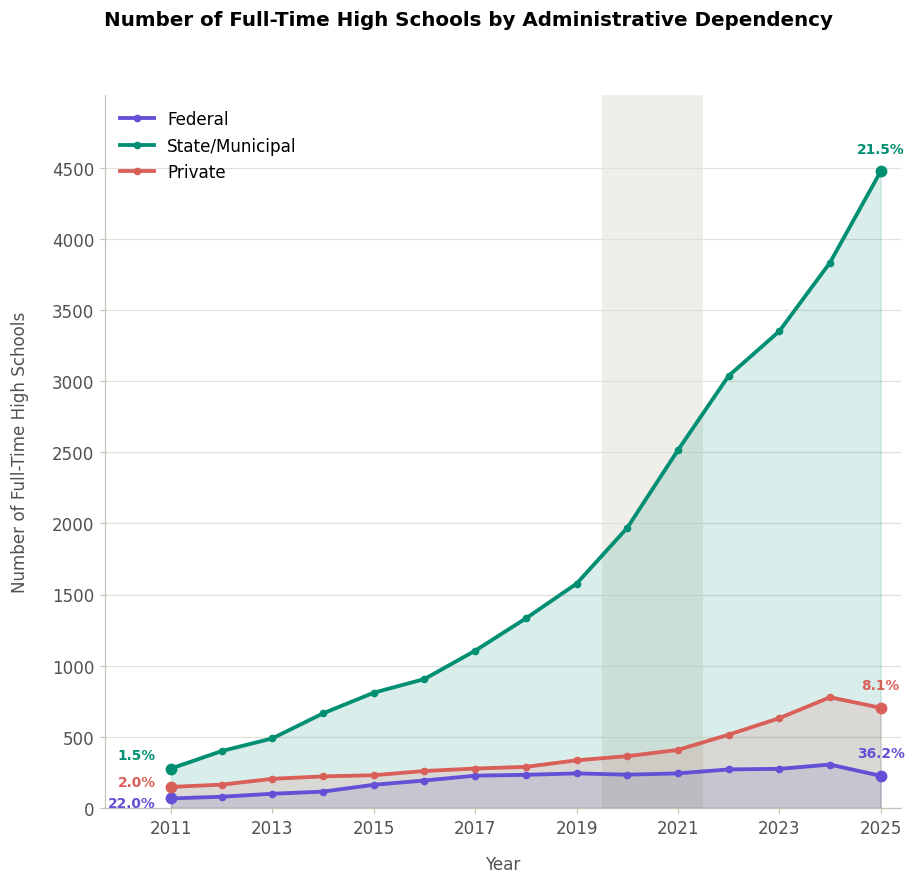

In [26]:
# ----------------------------------------------------------
# 1. CONFIGURAÇÃO DA FIGURA
# ----------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 9))

# Destaque do período pandêmico
sombra_pandemia(ax)

# Posições dos percentuais no primeiro ano
# Formato: (deslocamento x, deslocamento y, alinhamento, ancoragem)

# [CORREÇÃO C3] em 2011 os rótulos de Federal e Privada se sobrepunham;
# agora ficam empilhados à esquerda do primeiro ponto, com folga vertical.
POSICOES_INICIO = {
    "Estadual/Municipal": (-10, 4, "right", "bottom"),
    "Privada": (-10, 3, "right", "center"),
    "Federal": (-10, -3, "right", "center")
}


# ----------------------------------------------------------
# 2. ÁREAS PREENCHIDAS E LINHAS POR DEPENDÊNCIA
# ----------------------------------------------------------

for dep in DEPS_GRAFICO1:

    # Dados da dependência
    dados = (
        tabela_grafico1.loc[
            tabela_grafico1["DEP"] == dep
        ]
        .sort_values("ANO")
        .copy()
    )

    if dados.empty:
        continue

    anos = dados["ANO"].to_numpy()
    valores = dados["integrais"].to_numpy()

    cor = COR_DEPENDENCIA[dep]

    # Área preenchida
    ax.fill_between(
        anos,
        valores,
        0,
        color=cor,
        alpha=0.15,
        zorder=1
    )

    # Linha principal: quantidade absoluta
    ax.plot(
        anos,
        valores,
        color=cor,
        linewidth=2.5,
        marker="o",
        markersize=4,
        label=TEXTOS["dependencias"][dep],
        zorder=2
    )

    # Destaque dos pontos inicial e final
    ax.scatter(
        [anos[0], anos[-1]],
        [valores[0], valores[-1]],
        color=cor,
        s=45,
        zorder=3
    )

    # ------------------------------------------------------
    # 3. RÓTULOS PERCENTUAIS
    # ------------------------------------------------------

    for pos in [0, -1]:

        linha = dados.iloc[pos]
        percentual = linha["pct_integrais"]

        if pd.isna(percentual):
            continue

        if pos == 0:

            # Primeiro ano: percentuais distribuídos ao lado
            dx, dy, ha, va = POSICOES_INICIO[dep]

        else:

            # Último ano: percentuais centralizados acima
            dx = 0
            dy = 10
            ha = "center"
            va = "bottom"

        ax.annotate(
            f"{percentual:.1f}%",
            xy=(linha["ANO"], linha["integrais"]),
            xytext=(dx, dy),
            textcoords="offset points",
            ha=ha,
            va=va,
            fontsize=9,
            fontweight="semibold",
            color=cor,
            annotation_clip=False,
            zorder=4
        )


# ----------------------------------------------------------
# 4. EIXOS E ESCALAS
# ----------------------------------------------------------

# Limites dinâmicos do eixo Y
maximo = tabela_grafico1["integrais"].max()

ax.set_ylim(
    bottom=0,
    top=maximo * 1.12
)

# Marcações do eixo Y em intervalos de 500
limite_marcas = int(np.ceil(maximo / 500) * 500)

ax.set_yticks(
    np.arange(0, limite_marcas + 1, 500)
)

# Eixo Y
ax.set_ylabel(
    "Number of Full-Time High Schools",
    labelpad=15
)

# Eixo X
ax.set_xlabel(
    TEXTOS["ano"],
    labelpad=12
)

# Marcações dos anos
eixo_anos(
    ax,
    sorted(tabela_grafico1["ANO"].unique().tolist())
)

# Espaço adicional antes e depois do período
ano_min = tabela_grafico1["ANO"].min()
ano_max = tabela_grafico1["ANO"].max()

ax.set_xlim(
    left=ano_min - 1.3,
    right=ano_max + 0.4
)


# ----------------------------------------------------------
# 5. ESTÉTICA E LEGENDA
# ----------------------------------------------------------

ax.grid(
    axis="y",
    color=GRADE
)

ax.grid(
    axis="x",
    visible=False
)

ax.legend(
    loc="upper left",
    frameon=False,
    ncol=1
)


# ----------------------------------------------------------
# 6. TÍTULO
# ----------------------------------------------------------

fig.suptitle(
    "Number of Full-Time High Schools by Administrative Dependency",
    x=0.52,
    y=0.95,
    ha="center",
    fontsize=13,
    fontweight="semibold"
)


# ----------------------------------------------------------
# 7. AJUSTE FINAL E EXPORTAÇÃO
# ----------------------------------------------------------

fig.tight_layout(
    rect=[0.04, 0.06, 0.98, 0.92]
)

salvar(
    fig,
    "g1_expansao_nacional_quantidade_escolas"
)

plt.show()

## 6. Gráfico 2

### Tabela

In [27]:
# ==========================================================
# GRÁFICO 2 — EXPANSÃO REGIONAL
# Escolas integrais por região
# ==========================================================


# ----------------------------------------------------------
# 1. SELEÇÃO DOS DADOS
# ----------------------------------------------------------

print(
    "Dependências disponíveis:",
    sorted(df_analise["DEP"].dropna().unique())
)

dados_grafico2 = (
    df_analise.loc[
        df_analise["DEP"].isin(DEPS_GRAFICO2)
        & df_analise["ANO"].between(*ANOS_EXPANSAO)
    ]
    .copy()
)

# Conferência de duplicatas escola-ano
duplicadas_grafico2 = int(
    dados_grafico2.duplicated(
        ["ANO", "CO_ESCOLA"]
    ).sum()
)

print(
    f"Duplicatas escola-ano na análise regional: "
    f"{duplicadas_grafico2}"
)

assert duplicadas_grafico2 == 0, (
    "Foram encontradas duplicatas escola-ano. "
    "Verifique os dados antes de agregar."
)


# ----------------------------------------------------------
# 2. AGREGAÇÃO POR REGIÃO E ANO
# ----------------------------------------------------------

tabela_grafico2 = (
    dados_grafico2
    .groupby(["REGIAO", "ANO"])
    .agg(
        escolas=("CO_ESCOLA", "nunique"),
        integrais=("INTEGRAL", "sum")
    )
    .reset_index()
)

# Percentual regional de escolas integrais
tabela_grafico2["pct_integrais"] = (
    100
    * tabela_grafico2["integrais"]
    / tabela_grafico2["escolas"]
)


# ----------------------------------------------------------
# 3. MATRIZ DE PERCENTUAIS REGIONAIS
# ----------------------------------------------------------

anos_grafico2 = sorted(
    tabela_grafico2["ANO"].unique().tolist()
)

percentuais_regionais = (
    tabela_grafico2
    .pivot(
        index="REGIAO",
        columns="ANO",
        values="pct_integrais"
    )
    .reindex(index=REGIOES)
    .reindex(columns=anos_grafico2)
    .astype(float)
)


# ----------------------------------------------------------
# 4. AGREGAÇÃO NACIONAL — BRASIL
# ----------------------------------------------------------

brasil_grafico2 = (
    dados_grafico2
    .groupby("ANO")
    .agg(
        escolas=("CO_ESCOLA", "nunique"),
        integrais=("INTEGRAL", "sum")
    )
)

# Percentual nacional
brasil_grafico2["pct_integrais"] = (
    100
    * brasil_grafico2["integrais"]
    / brasil_grafico2["escolas"]
)


# ----------------------------------------------------------
# 5. MATRIZ COMPLETA COM BRASIL
# ----------------------------------------------------------

NOME_BRASIL = "Brazil"

percentual_brasil = (
    brasil_grafico2["pct_integrais"]
    .reindex(anos_grafico2)
    .rename(NOME_BRASIL)
)

percentuais_completo = pd.concat([
    percentual_brasil.to_frame().T,
    percentuais_regionais
])


# ----------------------------------------------------------
# 6. EXPORTAÇÃO DAS TABELAS
# ----------------------------------------------------------

tabela_grafico2.to_csv(
    PASTA_SAIDA / "tab2_expansao_regional_ano.csv",
    index=False,
    encoding="utf-8-sig"
)

brasil_grafico2.to_csv(
    PASTA_SAIDA / "tab2_expansao_nacional_ano.csv",
    encoding="utf-8-sig"
)

percentuais_completo.to_csv(
    PASTA_SAIDA / "tab2_percentuais_regionais_brasil.csv",
    encoding="utf-8-sig"
)


# ----------------------------------------------------------
# 7. CONFERÊNCIA DOS RESULTADOS
# ----------------------------------------------------------

print("\nPERCENTUAL DE ESCOLAS INTEGRAIS POR REGIÃO E BRASIL:")

display(
    percentuais_completo.round(2)
)

print("\nCONTAGENS NACIONAIS:")

display(
    brasil_grafico2.round(2)
)

Dependências disponíveis: ['Estadual/Municipal', 'Federal', 'Privada']
Duplicatas escola-ano na análise regional: 0

PERCENTUAL DE ESCOLAS INTEGRAIS POR REGIÃO E BRASIL:


ANO,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Brazil,1.47,2.12,2.57,3.47,4.18,4.64,5.61,6.73,7.94,9.92,12.58,15.07,16.44,18.74,21.53
Norte,1.31,1.65,1.92,2.76,3.4,2.46,3.61,3.64,5.07,5.62,6.08,7.18,7.71,9.75,11.9
Nordeste,3.69,5.54,6.35,7.44,8.72,9.44,10.96,13.51,16.5,19.94,21.98,24.53,26.38,31.44,35.3
Centro-Oeste,0.83,0.7,1.59,2.23,2.2,2.24,4.74,6.82,7.68,10.01,12.41,17.42,19.4,19.34,19.57
Sudeste,0.3,0.65,1.1,2.14,2.89,3.89,4.55,5.36,5.86,7.98,12.6,16.03,17.76,19.19,21.24
Sul,1.14,1.28,1.2,1.67,1.84,1.6,1.74,1.65,2.0,2.27,2.65,2.75,3.1,4.83,8.86



CONTAGENS NACIONAIS:


,escolas,integrais,pct_integrais
ANO,,,
2011,18810,277,1.47
2012,18902,400,2.12
2013,19006,489,2.57
2014,19160,665,3.47
2015,19367,810,4.18
2016,19527,906,4.64
2017,19706,1105,5.61
2018,19781,1332,6.73
2019,19840,1576,7.94


### Gráfico

Salvo: figuras_poster\g2_expansao_regional_heatmap.png / .svg


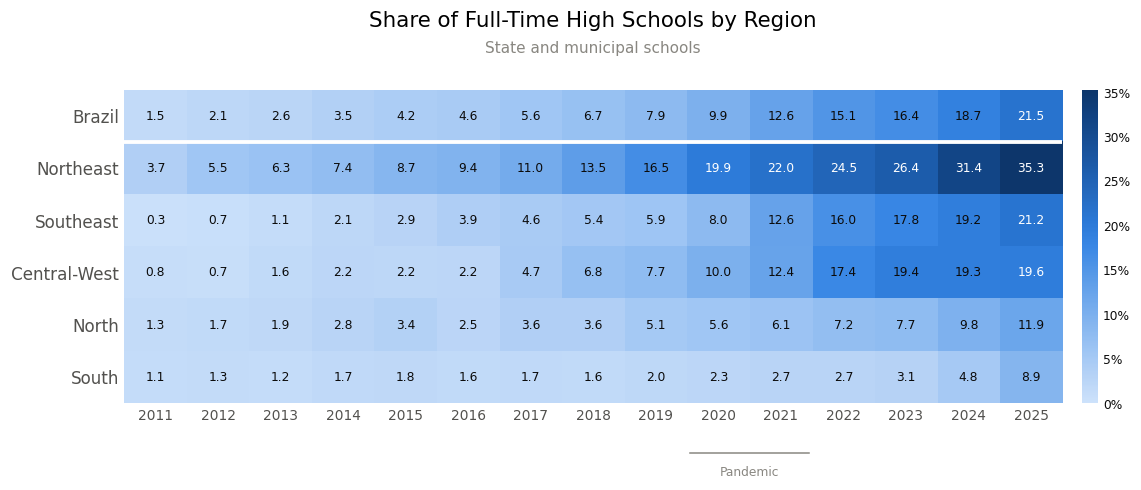

Salvo: figuras_poster\g2_expansao_regional_heatmap.png / .svg


In [28]:
# ==========================================================
# GRÁFICO 2 — MAPA DE CALOR REGIONAL
# Participação das escolas integrais
# ==========================================================
from matplotlib.ticker import PercentFormatter

# ----------------------------------------------------------
# 1. ORGANIZAÇÃO DA MATRIZ
# ----------------------------------------------------------

# Ordenar regiões pelo percentual do último ano
ordem_regioes = (
    percentuais_regionais[anos_grafico2[-1]]
    .sort_values(
        ascending=False,
        na_position="last"
    )
    .index.tolist()
)

# Brasil sempre aparece primeiro
matriz_grafico2 = pd.concat([
    percentuais_completo.loc[[NOME_BRASIL]],
    percentuais_completo.loc[ordem_regioes]
]).astype(float)

# Tradução dos nomes das regiões
TRADUCAO_REGIOES = {
    "Nordeste": "Northeast",
    "Sudeste": "Southeast",
    "Centro-Oeste": "Central-West",
    "Norte": "North",
    "Sul": "South"
}

matriz_grafico2 = matriz_grafico2.rename(
    index=TRADUCAO_REGIOES
)

linhas_grafico2 = matriz_grafico2.index.tolist()


# ----------------------------------------------------------
# 2. CONSTRUÇÃO DO MAPA DE CALOR
# ----------------------------------------------------------

cmap = LinearSegmentedColormap.from_list(
    "azul",
    RAMPA_AZUL
)

vmax = max(
    float(np.nanmax(matriz_grafico2.to_numpy())),
    1
)

fig, ax = plt.subplots(
    figsize=(11, 0.55 * len(linhas_grafico2) + 1.6)
)

im = ax.imshow(
    matriz_grafico2.to_numpy(),
    aspect="auto",
    cmap=cmap,
    vmin=0,
    vmax=vmax
)


# ----------------------------------------------------------
# ESCALA DE CORES
# ----------------------------------------------------------

cbar = fig.colorbar(
    im,
    ax=ax,
    orientation="vertical",
    fraction=0.025,
    pad=0.02
)

cbar.ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=100, decimals=0)
)


cbar.ax.tick_params(
    labelsize=8,
    colors=TINTA,
    length=0
)

cbar.outline.set_visible(False)

# ----------------------------------------------------------
# 3. EIXOS E IDENTIFICAÇÃO DAS REGIÕES
# ----------------------------------------------------------

ax.set_xticks(
    range(len(anos_grafico2))
)

ax.set_xticklabels(
    anos_grafico2,
    fontsize=9
)

ax.set_yticks(
    range(len(linhas_grafico2))
)

ax.set_yticklabels(
    linhas_grafico2
)

ax.tick_params(length=0)
ax.grid(False)

# Todos os nomes das regiões com peso normal
for label in ax.get_yticklabels():
    label.set_fontweight("normal")

# Separador visual entre Brasil e regiões
ax.axhline(
    0.5,
    color="white",
    linewidth=2.5,
    zorder=5
)

# Remover bordas
for s in ax.spines.values():
    s.set_visible(False)


# ----------------------------------------------------------
# 4. VALORES NAS CÉLULAS
# ----------------------------------------------------------

for i in range(len(linhas_grafico2)):
    for j in range(len(anos_grafico2)):

        valor = matriz_grafico2.iat[i, j]

        if pd.notna(valor):

            ax.text(
                j,
                i,
                f"{valor:.1f}",
                ha="center",
                va="center",
                fontsize=8,
                fontweight="normal",
                color="white" if valor > 0.55 * vmax else TINTA,
                zorder=4
            )


# ----------------------------------------------------------
# 5. DESTAQUE DO PERÍODO PANDÊMICO
# ----------------------------------------------------------

# Manter os limites originais da matriz
ax.set_ylim(
    len(linhas_grafico2) - 0.5,
    -0.5
)

if all(ano in anos_grafico2 for ano in ANOS_PANDEMIA):

    j0 = anos_grafico2.index(ANOS_PANDEMIA[0])
    j1 = anos_grafico2.index(ANOS_PANDEMIA[1])

    # Coordenadas: x em dados e y relativo ao eixo
    trans = ax.get_xaxis_transform()

    # Traço abaixo dos anos
    ax.plot(
        [j0 - 0.45, j1 + 0.45],
        [-0.16, -0.16],
        transform=trans,
        color=APAGADO,
        lw=1,
        clip_on=False
    )

    # Identificação do período
    ax.text(
        (j0 + j1) / 2,
        -0.20,
        "Pandemic",
        transform=trans,
        ha="center",
        va="top",
        fontsize=8,
        color=APAGADO
    )


# ----------------------------------------------------------
# 6. TÍTULO E SUBTÍTULO
# ----------------------------------------------------------

# Ajustar a área do gráfico antes de posicionar os textos
fig.tight_layout(
    rect=[0.02, 0.04, 0.98, 0.87]
)

# Centro horizontal da área do mapa de calor
posicao = ax.get_position()
centro_mapa = (posicao.x0 + posicao.x1) / 2

# Título
fig.text(
    centro_mapa,
    0.98,
    "Share of Full-Time High Schools by Region",
    ha="center",
    va="top",
    fontsize=14
)

# Subtítulo
fig.text(
    centro_mapa,
    0.925,
    "State and municipal schools",
    ha="center",
    va="top",
    fontsize=10,
    color=APAGADO
)


# ----------------------------------------------------------
# 7. EXPORTAÇÃO
# ----------------------------------------------------------

salvar(
    fig,
    "g2_expansao_regional_heatmap"
)

plt.show()


# ----------------------------------------------------------
# 7. AJUSTE FINAL E EXPORTAÇÃO
# ----------------------------------------------------------

fig.tight_layout(
    rect=[0.02, 0.15, 0.98, 0.87]
)

salvar(
    fig,
    "g2_expansao_regional_heatmap"
)

plt.show()

## 7. Gráfico 3 — Reprovação e abandono por modalidade, ano a ano (escolas estaduais e municipais)

**Linhas:** número de alunos reprovados (ou que abandonaram), somado nas escolas de cada modalidade, em milhares.

**Rótulos no último ano:** taxa da modalidade naquele ano. Para cada modalidade e ano, soma dos reprovados (ou que abandonaram) de todas as escolas ÷ soma dos alunos com situação final (aprovados + reprovados + abandonos) dessas escolas. É a fórmula da taxa do INEP aplicada ao conjunto, e equivale à média das taxas das escolas ponderada pelo número de alunos.

Como a modalidade Regular tem muito mais alunos, ela domina as linhas; a comparação entre modalidades se faz pelos rótulos de taxa.

> **[CORREÇÃO C1]** A categoria **Misto** reúne escolas com **10% a 90%** das matrículas do EM em tempo integral (Regular: menos de 10%; Integral: mais de 90%), conforme a coluna `ENS_PRED_EM` da base. O número de escolas-ano de cada modalidade por ano está na tabela da seção 3.

### Anos do eixo x

Lista de anos usada nos eixos do Gráfico 3, criada a partir da própria amostra.

In [29]:
# Todos os anos presentes na amostra (no original: ANOS = list(pct1.index), definido no Gráfico 1)
ANOS = sorted(df["ANO"].unique())
print(f"Anos: {ANOS[0]}–{ANOS[-1]} ({len(ANOS)} anos)")

Anos: 2011–2025 (15 anos)


In [30]:
# [CORREÇÃO C4] numeração: este é o Gráfico 3 (antes "Gráfico 2")
g3 = df[df["DEP"].isin(DEPS_GRAFICO3)]
tab3 = (g3.groupby(["ENS_PRED_EM", "ANO"])
          .agg(escolas=("CO_ESCOLA", "size"), alunos=("ALUNOS", "sum"),
               reprovados=("QT_REP_EM_TOTAL", "sum"), abandonos=("QT_ABN_EM_TOTAL", "sum"))
          .reset_index())
tab3["TX_REP"] = 100 * tab3["reprovados"] / tab3["alunos"]
tab3["TX_ABN"] = 100 * tab3["abandonos"] / tab3["alunos"]
tab3.to_csv(SAIDA / "tab3_taxas_modalidade_ano.csv", index=False, encoding="utf-8-sig")
DEPS3_TXT = nome_deps(DEPS_GRAFICO3)

display(tab3.pivot(index="ANO", columns="ENS_PRED_EM", values=["TX_REP", "TX_ABN"])
            .reindex(columns=MODALIDADES, level=1).round(2))


def grafico3(valor, nome_arquivo, titulo, rotulo_y, subtitulo, formato_fim, escala=1.0):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
    finais = {}
    for ax, (col_tx, col_abs) in zip(axes, [("TX_REP", "reprovados"), ("TX_ABN", "abandonos")]):
        col = col_tx if valor == "pct" else col_abs
        sombra_pandemia(ax)
        finais[ax] = ([], [])
        for m in MODALIDADES:
            s = tab3[tab3["ENS_PRED_EM"] == m].set_index("ANO")[col] / escala
            if s.empty:
                continue
            ax.plot(s.index, s, marker="o", color=COR_MOD[m], label=TEXTOS["modalidades"][m])
            # Rótulo final: taxa (%) do último ano, posicionado no último ponto da linha
            taxa_fim = tab3[tab3["ENS_PRED_EM"] == m].set_index("ANO")[col_tx].iloc[-1]
            finais[ax][0].append(s.iloc[-1])
            finais[ax][1].append(formato_fim(TEXTOS["modalidades"][m], taxa_fim))
        eixo_anos(ax, ANOS)
        ax.set_ylim(0, None)
        ax.set_title(TEXTOS["g3_sub"].format(taxa=TEXTOS["taxas"][col_tx]), loc="left", fontsize=11)
        ax.set_xlabel(TEXTOS["ano"])
    axes[0].set_ylabel(rotulo_y)
    for ax, (vals, txts) in finais.items():          # rótulos só depois de a escala comum estar fixa
        rotulos_finais(ax, ANOS[-1], vals, txts, folga=0.06)
    if valor == "pct":
        axes[0].yaxis.set_major_formatter(PCT)
    else:
        axes[0].yaxis.set_major_formatter(MIL)
    fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", bbox_to_anchor=(0.99, 1.0), ncol=3, fontsize=9)
    fig.suptitle(titulo, x=0.01, y=0.995, ha="left", fontsize=12, fontweight="bold", color=TINTA)
    # Subtítulo: deixa claro que só entram escolas estaduais e municipais
    fig.text(0.01, 0.925, subtitulo, ha="left", va="top", fontsize=10, color=APAGADO)
    fig.tight_layout(rect=(0, 0, 1, 0.90), w_pad=4)
    salvar(fig, nome_arquivo)
    plt.show()

TX_REP                          TX_ABN                    
ENS_PRED_EM    Regular      Misto  Integral    Regular     Misto  Integral
ANO                                                                       
2011         14.168742  11.859538  6.298379  11.014569  9.201949  1.136641
2012         13.308449  10.188321  6.106657  10.801049  7.855879  1.186531
2013         12.975855  10.318448  6.675794   9.567551  6.952609  1.036058
2014         13.455194   10.68353  5.770408   9.026684  6.281948  1.736081
2015         12.783871  10.324417  6.020837   8.190032  5.456052  1.305591
2016         13.446864   9.767344   4.78225   7.916028  6.252666  1.659873
2017         12.319721   9.483941  4.282163   7.331792  6.133196  1.090621
2018         12.095251   9.783629  4.350296   7.433385  6.240554  1.108592
2019         10.536642   8.663732  4.108779   5.820423  5.295248  1.034505
2020           2.89038   3.465565  0.920369   2.730275  2.393914  0.583933
2021          4.647383   4.518953  2.094546   6.318559  4.953804  1.854745
2022          9.408659   7.068172  3.229344   7.231752  6.125775  2.324212
2023          6.451864   4.256307  2.606649   4.230008  3.674182  1.354253
2024          6.390962    4.27589  2.696071   4.037454  3.633781  1.383197
2025          3.626844   2.393663  1.467999   2.972424  1.999587  1.355917

### Gráfico — número de alunos, com a taxa no último ano

Salvo: figuras_poster\g3_reprovacao_abandono_modalidade.png / .svg


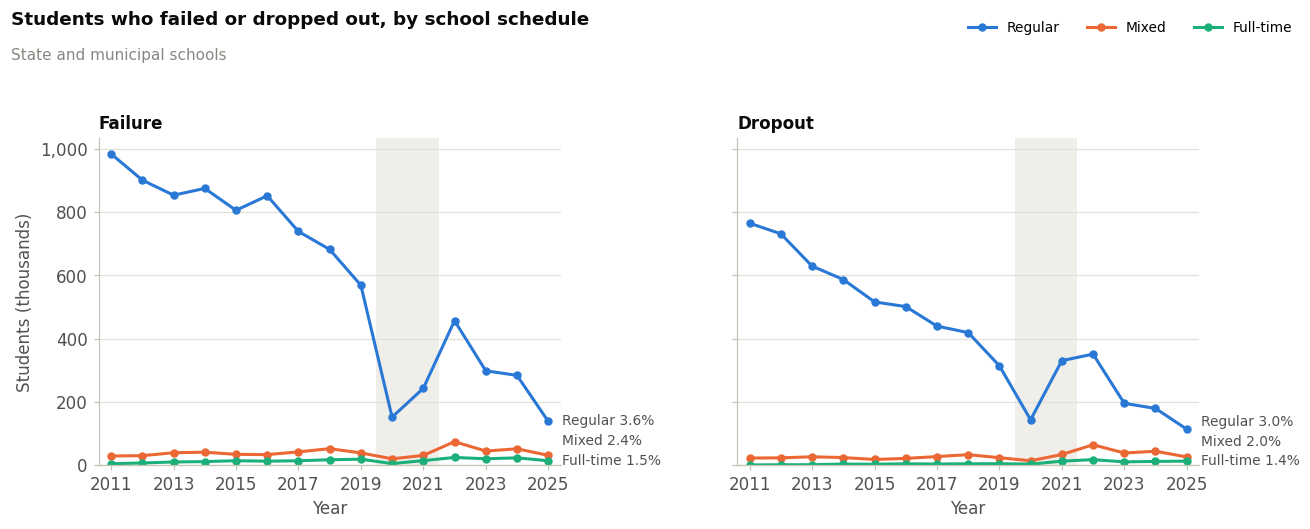

In [31]:
grafico3("abs", "g3_reprovacao_abandono_modalidade", TEXTOS["g3_titulo_abs"], TEXTOS["g3_y_abs"],
         TEXTOS["subtitulo_publicas"], lambda m, v: f"{m} {v:.1f}%", escala=1000)

## 8. Gráfico 4 — Boxplots pré (2016–2019) e pós-pandemia (2022–2025), escolas estaduais e municipais

Dois painéis: reprovação e abandono, só escolas estaduais e municipais (`DEPS_GRAFICO4`). Em cada painel, as três modalidades, com a caixa clara (pré) ao lado da escura (pós).

Detalhes:
- **os dois painéis com a mesma escala vertical** (o eixo y vai até o maior bigode do gráfico inteiro, então nada fica cortado);
- pesos por número de alunos (ver seção 4) — configurável em `PESO_BOXPLOT`;
- caixas com poucas unidades ficam hachuradas e mostram o n.

Os quartis ponderados são calculados à mão (o `boxplot` do matplotlib não aceita pesos); o desenho usa `ax.bxp` com essas estatísticas.

In [32]:
def periodo_do_ano(ano):
    for k, (a, b) in PERIODOS.items():
        if a <= ano <= b:
            return k
    return None

# [CORREÇÃO C4] numeração: este é o Gráfico 4 (antes "Gráfico 3")
base4 = df.assign(PERIODO=df["ANO"].map(periodo_do_ano))
base4 = base4[base4["PERIODO"].notna() & (base4["ALUNOS"] > 0) & (base4["MAT_EM"] >= MIN_MATRICULAS_BOXPLOT)]

if UNIDADE_BOX == "escola-periodo":
    # taxa acumulada da escola no período (se a escola mudou de modalidade no meio, vira duas unidades)
    base4 = (base4.groupby(["CO_ESCOLA", "PERIODO", "DEP", "ENS_PRED_EM"])
                  [["ALUNOS", "QT_REP_EM_TOTAL", "QT_ABN_EM_TOTAL"]].sum().reset_index())
    base4["TX_REP"] = 100 * base4["QT_REP_EM_TOTAL"] / base4["ALUNOS"]
    base4["TX_ABN"] = 100 * base4["QT_ABN_EM_TOTAL"] / base4["ALUNOS"]


def quantis(v, w, qs):
    """Quantis ponderados (interpolação linear). Sem peso, igual ao np.percentile."""
    if w is None:
        return np.percentile(v, np.array(qs) * 100)
    o = np.argsort(v)
    v, w = v[o], w[o]
    acum = np.cumsum(w)
    p = (acum - 0.5 * w) / acum[-1]
    return np.interp(qs, p, v)


def estat_caixa(v, w=None):
    v = np.asarray(v, dtype=float)
    w = None if w is None else np.asarray(w, dtype=float)
    q1, med, q3 = quantis(v, w, [0.25, 0.5, 0.75])
    iqr = q3 - q1
    return {"q1": q1, "med": med, "q3": q3,
            "whislo": v[v >= q1 - 1.5 * iqr].min(), "whishi": v[v <= q3 + 1.5 * iqr].max(),
            "fliers": [], "n": len(v), "media_pond": np.average(v, weights=w)}


estats = []
for taxa in ("TX_REP", "TX_ABN"):
    for dep in DEPS_GRAFICO4:
        for mod in MODALIDADES:
            for per in PERIODOS:
                s = base4[(base4["DEP"] == dep) & (base4["ENS_PRED_EM"] == mod) & (base4["PERIODO"] == per)]
                if s.empty:
                    continue
                w = s["ALUNOS"].to_numpy() if PESO_BOXPLOT == "alunos" else None
                estats.append({"taxa": taxa, "dep": dep, "mod": mod, "periodo": per,
                               **estat_caixa(s[taxa].to_numpy(), w)})
tab4 = pd.DataFrame(estats)
tab4.drop(columns="fliers").to_csv(SAIDA / "tab4_boxplots.csv", index=False, encoding="utf-8-sig")
display(tab4.drop(columns="fliers").set_index(["taxa", "dep", "mod", "periodo"]).round(2))

q1    med     q3  whislo  whishi      n  media_pond
taxa   dep                mod      periodo                                                       
TX_REP Estadual/Municipal Regular  pre      5.71  10.61  16.88     0.0   33.62  69121       12.16
                                   pos      1.20   4.35   9.76     0.0   22.59  52543        6.64
                          Misto    pre      3.34   7.73  13.43     0.0   28.48   4814        9.42
                                   pos      0.39   2.14   6.27     0.0   15.09  14503        4.38
                          Integral pre      0.97   2.80   5.93     0.0   13.33   4919        4.34
                                   pos      0.00   1.03   3.31     0.0    8.27  14691        2.45
TX_ABN Estadual/Municipal Regular  pre      1.97   5.78  10.67     0.0   23.72  69121        7.17
                                   pos      0.44   3.02   6.95     0.0   16.70  52543        4.73
                          Misto    pre      0.65   4.38   9.27     0.0   22.17   4814        5.98
                                   pos      0.17   2.05   5.52     0.0   13.51  14503        3.75
                          Integral pre      0.00   0.00   0.64     0.0    1.60   4919        1.18
                                   pos      0.00   0.22   1.91     0.0    4.77  14691        1.58

Salvo: figuras_poster\g4_boxplots_rep_abn_pre_pos.png / .svg


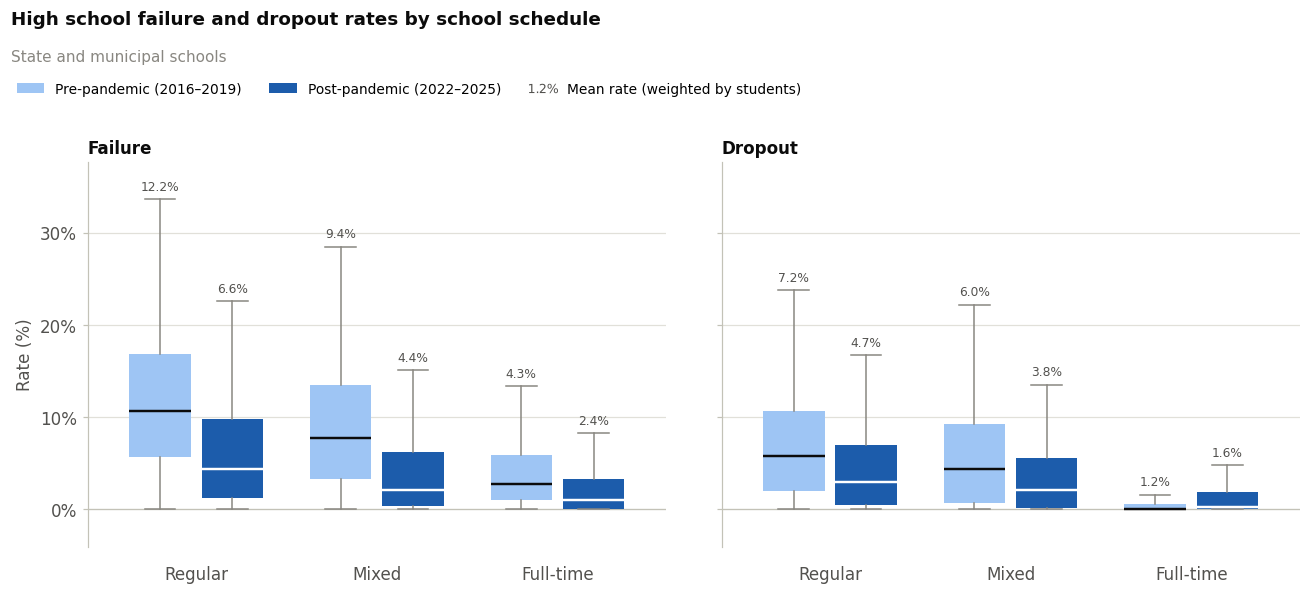

In [33]:
from matplotlib.lines import Line2D

assert len(DEPS_GRAFICO4) == 1, "O Gráfico 4 foi desenhado para uma única dependência (DEPS_GRAFICO4)."
dep = DEPS_GRAFICO4[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), sharey=True)
desloc = {"pre": -0.2, "pos": 0.2}
x_mod = np.arange(len(MODALIDADES))
unid_txt = TEXTOS["unidades"][UNIDADE_BOX]

# Mesma escala vertical para reprovação e abandono: topo = maior bigode do gráfico inteiro
topo = tab4["whishi"].max() if not tab4.empty else 1

for i, taxa in enumerate(("TX_REP", "TX_ABN")):
    linha = tab4[tab4["taxa"] == taxa]
    ax = axes[i]
    for per in PERIODOS:
        sel = linha[(linha["dep"] == dep) & (linha["periodo"] == per)]
        if sel.empty:
            continue
        pos = [x_mod[MODALIDADES.index(m)] + desloc[per] for m in sel["mod"]]
        caixas = ax.bxp(sel.to_dict("records"), positions=pos, widths=0.34, patch_artist=True,
                        showfliers=False, manage_ticks=False,
                        medianprops=dict(color=TINTA if per == "pre" else "white", lw=1.6),
                        whiskerprops=dict(color=APAGADO, lw=1), capprops=dict(color=APAGADO, lw=1),
                        boxprops=dict(lw=0))
        # Média de cada caixa escrita acima do bigode superior
        for p, media, topo_caixa in zip(pos, sel["media_pond"], sel["whishi"]):
            txt_media = f"{media:.1f}%"
            if IDIOMA == "pt":
                txt_media = txt_media.replace(".", ",")
            ax.text(p, topo_caixa + 0.02 * topo, txt_media, ha="center", va="bottom",
                    fontsize=8, color=TINTA_2)
        for patch, mediana, n, p in zip(caixas["boxes"], caixas["medians"], sel["n"], pos):
            patch.set_facecolor(COR_PERIODO[per])
            if n < MIN_N_CELULA:
                patch.set_alpha(0.45); patch.set_hatch("////"); patch.set_edgecolor(TINTA_2)
                mediana.set_color(TINTA)
                ax.text(p, -0.04 * topo, f"n={n}", ha="center", va="top", fontsize=7, color=APAGADO)
    ax.set_xticks(x_mod, [TEXTOS["modalidades"][m] for m in MODALIDADES])
    ax.tick_params(axis="x", length=0, pad=12)
    ax.set_xlim(-0.6, len(MODALIDADES) - 0.4)
    ax.set_ylim(-0.12 * topo, topo * 1.12)   # folga para os rótulos de média
    ax.yaxis.set_major_locator(mticker.MaxNLocator(nbins=6, steps=[1, 2, 5, 10]))
    ax.yaxis.set_major_formatter(PCT)
    ax.spines["bottom"].set_visible(False)
    ax.axhline(0, color=EIXO, lw=0.8, zorder=1)
    ax.set_title(TEXTOS["taxas"][taxa], loc="left", fontsize=11)
    if i == 0:
        ax.set_ylabel(TEXTOS["g3_y_pct"])

legenda = [Patch(facecolor=COR_PERIODO[p], label=f"{TEXTOS['periodos'][p]} ({a}–{b})") for p, (a, b) in PERIODOS.items()]

# Entrada da legenda explicando o número acima de cada caixa
exemplo_media = "1.2%" if IDIOMA == "en" else "1,2%"
if PESO_BOXPLOT == "alunos":
    rotulo_media = {"en": "Mean rate (weighted by students)",
                    "pt": "Taxa média (ponderada por alunos)"}[IDIOMA]
else:
    rotulo_media = {"en": "Mean rate", "pt": "Taxa média"}[IDIOMA]
legenda.append(Line2D([], [], linestyle="none", color=TINTA_2,
                      marker=rf"$\mathregular{{{exemplo_media.replace('%', chr(92) + '%')}}}$",
                      markersize=19, markeredgewidth=0, label=rotulo_media))

fig.suptitle(TEXTOS["g4_titulo"], x=0.01, ha="left", y=0.995, fontsize=12, fontweight="bold", color=TINTA)
# Subtítulo: deixa claro que só entram escolas estaduais e municipais
fig.text(0.01, 0.93, TEXTOS["subtitulo_publicas"], ha="left", va="top", fontsize=10, color=APAGADO)
fig.legend(handles=legenda, loc="upper left", ncol=3, bbox_to_anchor=(0.005, 0.895), fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.87), w_pad=3)
salvar(fig, "g4_boxplots_rep_abn_pre_pos")
plt.show()


### Sensibilidade da escolha do peso (Gráfico 4)

Medianas de cada caixa em três versões. Se as diferenças entre modalidades e entre períodos apontam na mesma direção nas três colunas, a conclusão do gráfico não depende da escolha do peso.

In [34]:
b = df.assign(PERIODO=df["ANO"].map(periodo_do_ano))
b = b[b["PERIODO"].notna() & (b["ALUNOS"] > 0) & b["DEP"].isin(DEPS_GRAFICO4)]
linhas_sens = []
for (dep, mod, per), s in b.groupby(["DEP", "ENS_PRED_EM", "PERIODO"]):
    grande = s[s["MAT_EM"] >= 51]
    for taxa in ("TX_REP", "TX_ABN"):
        linhas_sens.append({
            "taxa": taxa, "dep": dep, "mod": mod, "periodo": per,
            "sem peso (todas)": np.median(s[taxa]),
            "sem peso (≥ 51 matr.)": np.median(grande[taxa]) if len(grande) else np.nan,
            "peso = alunos": quantis(s[taxa].to_numpy(), s["ALUNOS"].to_numpy(), [0.5])[0],
            "n": len(s), "n (≥ 51)": len(grande),
        })
sens = (pd.DataFrame(linhas_sens)
          .assign(mod=lambda d: pd.Categorical(d["mod"], MODALIDADES),
                  dep=lambda d: pd.Categorical(d["dep"], DEPS_TODAS))
          .sort_values(["taxa", "dep", "mod", "periodo"], ascending=[False, True, True, False])
          .set_index(["taxa", "dep", "mod", "periodo"]))
sens.to_csv(SAIDA / "tab4_sensibilidade_peso.csv", encoding="utf-8-sig")
display(sens.round(2))

sem peso (todas)  sem peso (≥ 51 matr.)  peso = alunos      n  n (≥ 51)
taxa   dep                mod      periodo                                                                         
TX_REP Estadual/Municipal Regular  pre                  9.01                   9.42          10.61  69121     63469
                                   pos                  3.12                   3.61           4.35  52543     46110
                          Misto    pre                  6.88                   6.91           7.73   4814      4744
                                   pos                  1.94                   1.99           2.14  14503     13988
                          Integral pre                  2.83                   2.85           2.80   4919      4679
                                   pos                  0.88                   0.97           1.03  14691     13394
TX_ABN Estadual/Municipal Regular  pre                  5.04                   5.21           5.78  69121     63469
                                   pos                  2.44                   2.68           3.02  52543     46110
                          Misto    pre                  4.55                   4.53           4.38   4814      4744
                                   pos                  2.04                   2.06           2.05  14503     13988
                          Integral pre                  0.00                   0.00           0.00   4919      4679
                                   pos                  0.33                   0.41           0.22  14691     13394

## 9. Arquivos gerados

In [35]:
for p in sorted(SAIDA.iterdir()):
    print(p.name)

g1_1_expansao_nacional_dependencia_area.png
g1_1_expansao_nacional_dependencia_area.svg
g1_1b_quantidade_escolas_integrais.png
g1_1b_quantidade_escolas_integrais.svg
g1_2_integrais_regiao_heatmap.png
g1_2_integrais_regiao_heatmap.svg
g1_expansao_nacional_quantidade_escolas.png
g1_expansao_nacional_quantidade_escolas.svg
g2_expansao_regional_heatmap.png
g2_expansao_regional_heatmap.svg
g2a_taxas_modalidade_pct.png
g2a_taxas_modalidade_pct.svg
g2b_taxas_modalidade_abs.png
g2b_taxas_modalidade_abs.svg
g3_boxplots_rep_abn_pre_pos.png
g3_boxplots_rep_abn_pre_pos.svg
g3_reprovacao_abandono_modalidade.png
g3_reprovacao_abandono_modalidade.svg
g3a_taxas_modalidade_pct.png
g3a_taxas_modalidade_pct.svg
g3b_taxas_modalidade_abs.png
g3b_taxas_modalidade_abs.svg
g4_boxplots_rep_abn_pre_pos.png
g4_boxplots_rep_abn_pre_pos.svg
tab0_distribuicao_modalidades.csv
tab0_filtro.csv
tab0_filtro_grafico1.csv
tab0_filtro_rendimento.csv
tab0_filtros_amostra_comum.csv
tab1_1_expansao_nacional_dependencia.csv
ta